# 4. Modélisation et prédiction

Objectif : entraîner deux modèles de classification binaire (`Bullying` vs
`Not-Bullying`) sur les messages nettoyés, les évaluer, puis sauvegarder les
artefacts (vectoriseur + modèles) pour l'étape 5 (comparaison) et l'API.

## Préparation des features (vectorisation du texte)

In [11]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from pymongo import MongoClient
from pymongo.errors import ServerSelectionTimeoutError
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

pd.set_option("display.max_colwidth", 120)
sns.set_style("whitegrid")
load_dotenv("../.env")


True

In [12]:
MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
MONGO_DB_NAME = os.getenv("MONGO_DB_NAME", "cyberbullying_db")
MONGO_COLLECTION_PROCESSED = os.getenv("MONGO_COLLECTION_PROCESSED", "messages_processed")
PROCESSED_CSV_PATH = "../data/processed/cyberbullying_clean.csv"

try:
    client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    client.admin.command("ping")
    collection = client[MONGO_DB_NAME][MONGO_COLLECTION_PROCESSED]
    df = pd.DataFrame(list(collection.find({}, {"_id": 0})))
    print(f"Données chargées depuis MongoDB : {len(df)} lignes")
except ServerSelectionTimeoutError:
    df = pd.read_csv(PROCESSED_CSV_PATH)
    print(f"MongoDB indisponible, données chargées depuis {PROCESSED_CSV_PATH} : {len(df)} lignes")

df = df.dropna(subset=["text_clean"])
df.head()

Données chargées depuis MongoDB : 5740 lignes


,Text,text_clean,Label,Types,text_len
0,Ten outside soon doctor shake everyone treatment seat radio land.,ten outside soon doctor shake everyone treatment seat radio land,Not-Bullying,Aucun,10
1,my life has come to a standstill and at this point.,my life has come to a standstill and at this point,Not-Bullying,Aucun,11
2,girl this nigga make me sick to my stomach,girl this nigga make me sick to my stomach,Bullying,Ethnicity,9
3,I wanna fuck you,i wanna fuck you,Bullying,Sexual,4
4,"Oh hey, you should be ashamed of your disgusting self",oh hey you should be ashamed of your disgusting self,Not-Bullying,Aucun,10


In [13]:
# Cible binaire : 1 = Bullying, 0 = Not-Bullying
LABEL_MAP = {"Bullying": 1, "Not-Bullying": 0}
df["target"] = df["Label"].map(LABEL_MAP)

X_text = df["text_clean"].astype(str)
y = df["target"]

print(y.value_counts(normalize=True))

target
1    0.547038
0    0.452962
Name: proportion, dtype: float64


In [14]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
)

X = vectorizer.fit_transform(X_text)
print(f"Matrice TF-IDF : {X.shape[0]} messages x {X.shape[1]} features")

Matrice TF-IDF : 5740 messages x 5000 features


## Split train/test

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape[0]} messages")
print(f"Test  : {X_test.shape[0]} messages")

Train : 4592 messages
Test  : 1148 messages


In [16]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
    }

    print(f"--- {name} ---")
    for metric_name, value in metrics.items():
        print(f"{metric_name:10s}: {value:.4f}")
    print()
    print(classification_report(y_test, y_pred, target_names=["Not-Bullying", "Bullying"]))

    fig, ax = plt.subplots(figsize=(4, 4))
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Not-Bullying", "Bullying"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Matrice de confusion — {name}")
    plt.tight_layout()
    plt.show()

    return metrics

## Modèle 1 — Régression logistique

--- Régression logistique ---
accuracy  : 0.9059
precision : 0.8939
recall    : 0.9395
f1        : 0.9161

              precision    recall  f1-score   support

Not-Bullying       0.92      0.87      0.89       520
    Bullying       0.89      0.94      0.92       628

    accuracy                           0.91      1148
   macro avg       0.91      0.90      0.90      1148
weighted avg       0.91      0.91      0.91      1148



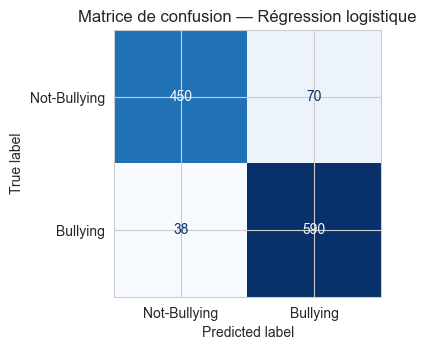

In [17]:
logreg_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
logreg_model.fit(X_train, y_train)

logreg_metrics = evaluate_model("Régression logistique", logreg_model, X_test, y_test)

## Modèle 2 — SVM linéaire (LinearSVC calibré)

--- SVM linéaire (LinearSVC calibré) ---
accuracy  : 0.9138
precision : 0.9088
recall    : 0.9363
f1        : 0.9224

              precision    recall  f1-score   support

Not-Bullying       0.92      0.89      0.90       520
    Bullying       0.91      0.94      0.92       628

    accuracy                           0.91      1148
   macro avg       0.91      0.91      0.91      1148
weighted avg       0.91      0.91      0.91      1148



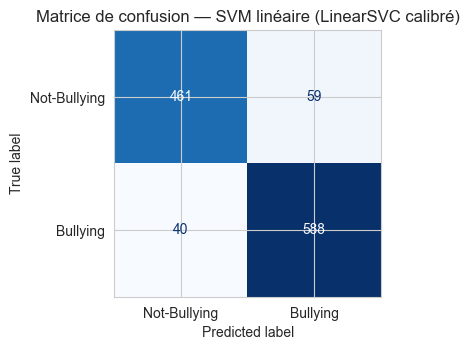

In [18]:
# LinearSVC n'expose pas predict_proba nativement -> on le calibre (Platt scaling)
# pour obtenir des probabilités exploitables comme score de confiance dans l'API.
svm_model = CalibratedClassifierCV(
    LinearSVC(class_weight="balanced", random_state=42), cv=3
)
svm_model.fit(X_train, y_train)

svm_metrics = evaluate_model("SVM linéaire (LinearSVC calibré)", svm_model, X_test, y_test)


In [ ]:
# Comparaison rapide des deux modèles 
comparison = pd.DataFrame({"LogisticRegression": logreg_metrics, "SVM (LinearSVC)": svm_metrics}).T
comparison.round(4)


,accuracy,precision,recall,f1
LogisticRegression,0.9059,0.8939,0.9395,0.9161
SVM (LinearSVC),0.9138,0.9088,0.9363,0.9224


## Sauvegarde des modèles (models_artifacts/)

In [ ]:
ARTIFACTS_DIR = "../models_artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

joblib.dump(vectorizer, os.path.join(ARTIFACTS_DIR, "tfidf_vectorizer.joblib"))
joblib.dump(logreg_model, os.path.join(ARTIFACTS_DIR, "logistic_regression_model.joblib"))
joblib.dump(svm_model, os.path.join(ARTIFACTS_DIR, "svm_model.joblib"))
joblib.dump(LABEL_MAP, os.path.join(ARTIFACTS_DIR, "label_map.joblib"))

old_nb_path = os.path.join(ARTIFACTS_DIR, "naive_bayes_model.joblib")
if os.path.exists(old_nb_path):
    os.remove(old_nb_path)

print("Artefacts sauvegardés dans", ARTIFACTS_DIR, ":")
for fname in sorted(os.listdir(ARTIFACTS_DIR)):
    print(" -", fname)


Artefacts sauvegardés dans ../models_artifacts :
 - .gitkeep
 - label_map.joblib
 - logistic_regression_model.joblib
 - svm_model.joblib
 - tfidf_vectorizer.joblib
